In [43]:
import pandas as pd
from sklearn.model_selection import train_test_split


* ID - Идентификатор настольной игры
* Name - Имя
* Year Published - Год публикации
* Min Players - Рекомендуемое минимальное количество игроков
* Max Players - Рекомендуемое максимальное количество игроков
* Play Time - Время игры
* Min Age - Рекомендуемый минимальный возраст игроков
* Users Rated - Количество пользователей, оценивших игру
* Rating Average - Средний рейтинг, полученный игрой (целевая переменная)
* BGG Rank - Рейтинг от BGG
* Complexity Average - Среднее значение сложности игры
* Owned Users - Количество зарегистрированных BGG владельцев игры
* Mechanics - Механика, используемая в игре
* Domains - Домены настольных игр, которым принадлежит игра

In [44]:
test = pd.read_csv('test_data.csv', sep=',', encoding='utf-8')
train = pd.read_csv('train_data.csv', sep=',', encoding='utf-8')


columns_test = test.columns
print(f"Всего пропусков: {test.isnull().sum().sum()}")
print(f"Всего (строк, столбцов): {test.shape}")

print(test.isnull().sum())
print()

columns_train = train.columns
print(f"Всего пропусков: {train.isnull().sum().sum()}")
print(f"Всего (строк, столбцов): {train.shape}")

print(train.isnull().sum())



Всего пропусков: 2920
Всего (строк, столбцов): (5086, 13)
ID                       6
Name                     0
Year Published           0
Min Players              0
Max Players              0
Play Time                0
Min Age                  0
Users Rated              0
BGG Rank                 0
Complexity Average       0
Owned Users              6
Mechanics              398
Domains               2510
dtype: int64

Всего пропусков: 8877
Всего (строк, столбцов): (15257, 14)
ID                      10
Name                     0
Year Published           1
Min Players              0
Max Players              0
Play Time                0
Min Age                  0
Users Rated              0
Rating Average           0
BGG Rank                 0
Complexity Average       0
Owned Users             17
Mechanics             1200
Domains               7649
dtype: int64


In [45]:
cols = ["Domains", "Mechanics"]

train[cols] = train[cols].fillna("Unknown")
test[cols] = test[cols].fillna("Unknown")

new_id = int(max(train["ID"].max(), test["ID"].max())) + 1
for table in [train, test]:
    for i in table.index:
        if pd.isna(table.loc[i, "ID"]):
            table.loc[i, "ID"] = new_id
            new_id += 1

median_owned = train["Owned Users"].median()
train["Owned Users"] = train["Owned Users"].fillna(median_owned)

median_year = train["Year Published"].median()
train["Year Published"] = train["Year Published"].fillna(median_year)

median_owned = test["Owned Users"].median()
test["Owned Users"] = test["Owned Users"].fillna(median_owned)

In [ ]:
print("Пропуски в train:")
print(train.isna().sum())
print()
print("Пропуски в test:")
print(test.isna().sum())


Пропуски в train:
ID                    0
Name                  0
Year Published        0
Min Players           0
Max Players           0
Play Time             0
Min Age               0
Users Rated           0
Rating Average        0
BGG Rank              0
Complexity Average    0
Owned Users           0
Mechanics             0
Domains               0
dtype: int64

Пропуски в test:
ID                    0
Name                  0
Year Published        0
Min Players           0
Max Players           0
Play Time             0
Min Age               0
Users Rated           0
BGG Rank              0
Complexity Average    0
Owned Users           0
Mechanics             0
Domains               0
dtype: int64


In [ ]:
y = train["Rating Average"]
x = train.drop(columns=["Rating Average", "ID"])

x_train, x_valid, y_train, y_valid = train_test_split(x, y,test_size=0.2,random_state=42)

print("Для обучения:", x_train.shape, y_train.shape)
print("Для проверки:", x_valid.shape, y_valid.shape)


Для обучения: (12205, 12) (12205,)
Для проверки: (3052, 12) (3052,)


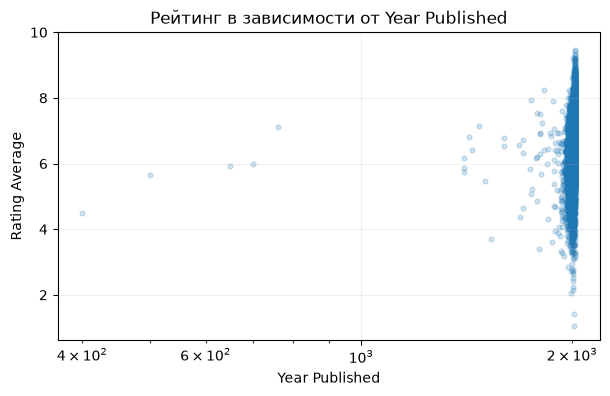

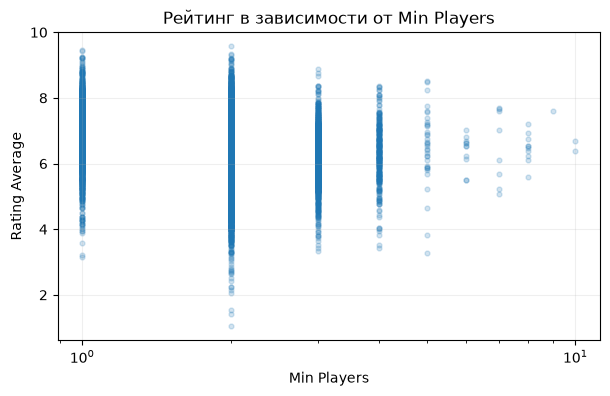

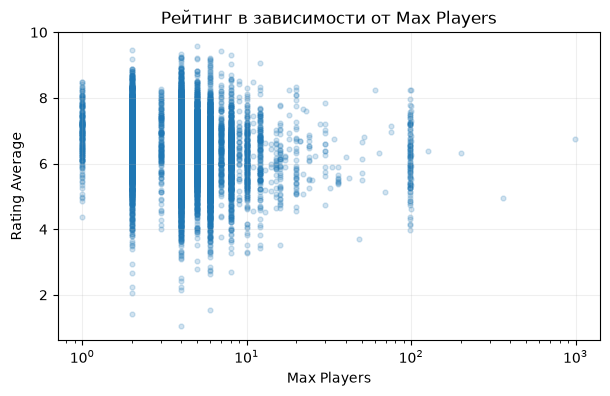

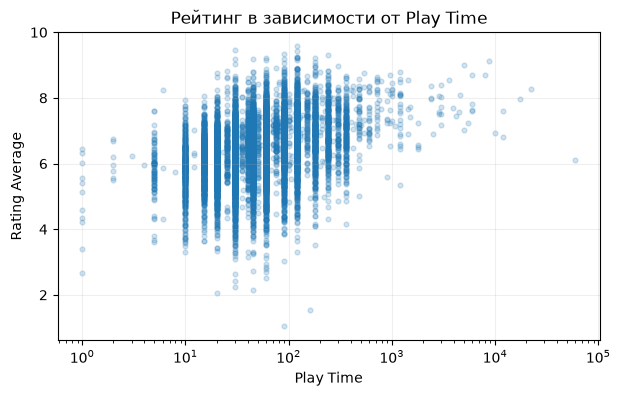

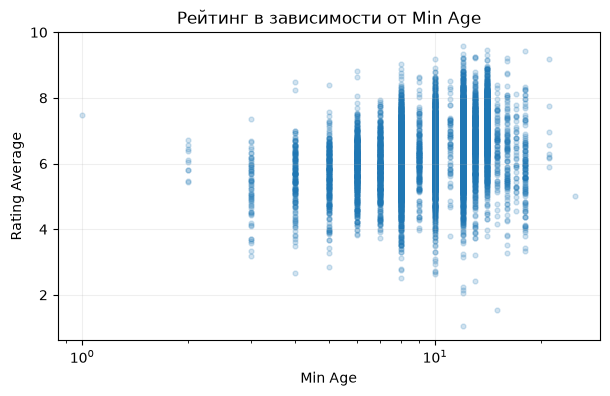

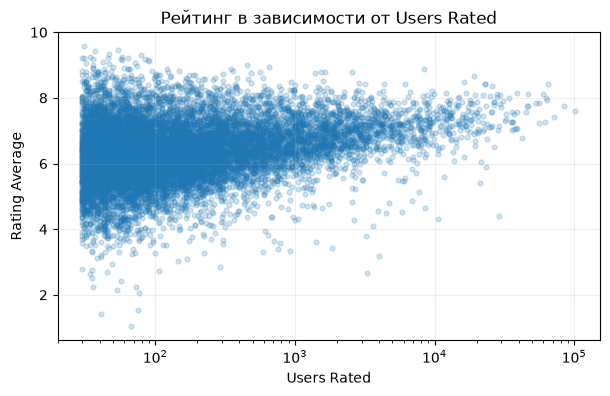

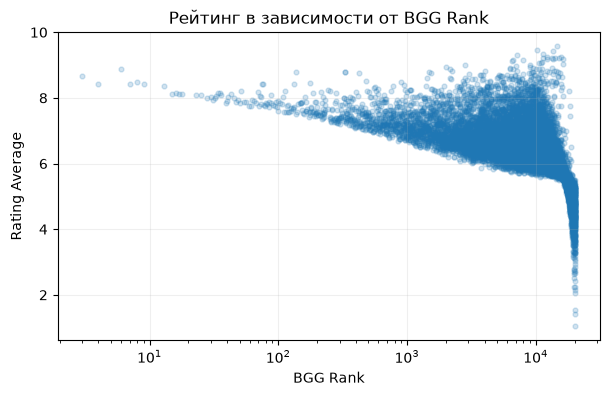

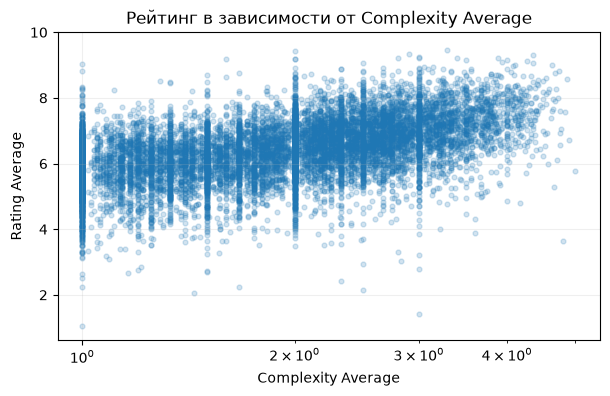

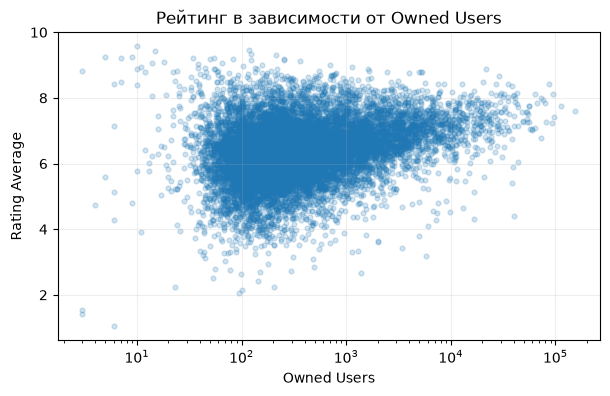

In [52]:
import matplotlib.pyplot as plt

def plot_feature(x, y, feature):
    plt.figure(figsize=(7, 4))
    plt.scatter(x[feature], y, alpha=0.2, s=12)

    plt.xlabel(feature)
    plt.ylabel("Rating Average")
    plt.title(f"Рейтинг в зависимости от {feature}")
    plt.grid(alpha=0.2)
    plt.xscale("log")
    plt.show()

for feature in x_train.select_dtypes(include="number").columns:
    plot_feature(x_train, y_train, feature)